# AI61201: Visual Computing with AI/ML
### **Programming Assignment 4**: Feature Design for Image Analysis

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Question 1 — Image Retrieval Using SIFT Features [10 marks]

**Dataset — ZuBuD (Zurich Buildings Database).** Download from the ETH Zurich CVL dataset page, https://vision.ee.ethz.ch/datsets.html (direct links below; note that the page URL is genuinely spelled `datsets`):

| File | Link | Size |
|---|---|---|
| Full database (1005 PNG images) | https://data.vision.ee.ethz.ch/cvl/aem/ZuBuD.tar.gz | ~486 MB |
| Query images (115 JPGs) | https://data.vision.ee.ethz.ch/cvl/aem/qimages.tar.gz | ~3.1 MB |
| Ground-truth mapping | https://ethz.ch/content/dam/ethz/special-interest/itet/cvl/vision-dam/datasets/Dataset-information/Zubud/zubud_groundtruth.txt | 931 B |

After extraction, you will have database images named `png-ZuBuD/object<bbbb>.view<vv>.png`, where `<bbbb>` is the building (object) ID and `<vv> ∈ {01, ..., 05}` is one of the 5 views of that building, and query images named `1000city/qimage/qimg<qqqq>.JPG`.

The ground-truth file has two tab-separated columns, `TEST` (the query index `qqqq`) and `TRAIN` (the corresponding correct building ID `bbbb`).

### (a) Dataset Preparation [1 mark]

Load the database and the query set. Parse the building ID of every database image from its filename, and parse the ground-truth file into a mapping from query index to true building ID.

Report the following:
- Number of database images
- Number of distinct buildings
- Number of views per building
- Number of query images

Note and report any non-image files present in the archives that you had to skip, and the fact that the query images differ from the database images in format and resolution. Resize or convert the images as you see fit, and state what you did.

In [2]:
import re
import tarfile
import cv2
from pathlib import Path
from collections import Counter

# Dataset paths
data_dir = Path("ZuBuD_dataset")
database_archive = data_dir / "ZuBuD.tar.gz"
query_archive = data_dir / "qimages.tar.gz"
gt_path = data_dir / "zubud_groundtruth.txt"

database_root = data_dir / "database"
query_root = data_dir / "queries"

# Extract archives only if images are not already available
if not database_root.exists() or not any(database_root.rglob("object*.view*.png")):
    database_root.mkdir(parents=True, exist_ok=True)
    with tarfile.open(database_archive, "r:gz") as archive:
        archive.extractall(database_root, filter="data")

if not query_root.exists() or not any(query_root.rglob("qimg*.JPG")):
    query_root.mkdir(parents=True, exist_ok=True)
    with tarfile.open(query_archive, "r:gz") as archive:
        archive.extractall(query_root, filter="data")

# Locate all files
database_files = [p for p in database_root.rglob("*") if p.is_file()]
query_files = [p for p in query_root.rglob("*") if p.is_file()]

# Parse database filenames: object<building_id>.view<view_id>.png
database_images = {}
views_per_building = {}

for path in database_files:
    match = re.search(r"object(\d+)\.view(\d+)\.png$", path.name, re.I)
    if match:
        building_id = int(match.group(1))
        view_id = int(match.group(2))

        database_images[path] = (building_id, view_id)
        views_per_building.setdefault(building_id, []).append(view_id)

# Parse query filenames: qimg<query_index>.JPG
query_images = {}

for path in query_files:
    match = re.search(r"qimg(\d+)\.jpg$", path.name, re.I)
    if match:
        query_index = int(match.group(1))
        query_images[query_index] = path

# Parse ground truth: TEST -> TRAIN
ground_truth = {}

with open(gt_path, "r", encoding="utf-8-sig") as file:
    for line in file:
        columns = line.strip().split()
        if len(columns) < 2 or columns[0].upper() == "TEST":
            continue
        try:
            query_index = int(columns[0])
            building_id = int(columns[1])
            ground_truth[query_index] = building_id
        except ValueError:
            continue

# Inspect image formats and resolutions using OpenCV
database_formats = Counter()
database_sizes = Counter()
query_formats = Counter()
query_sizes = Counter()

for path in database_images:
    img_cv = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img_cv is not None:
        database_formats[path.suffix.upper()] += 1
        height, width = img_cv.shape[:2]
        database_sizes[(width, height)] += 1

for path in query_images.values():
    img_cv = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img_cv is not None:
        query_formats[path.suffix.upper()] += 1
        height, width = img_cv.shape[:2]
        query_sizes[(width, height)] += 1

# Identify non-image files that were skipped
recognized_files = set(database_images) | set(query_images.values())

non_image_files = [
    str(path)
    for path in database_files + query_files
    if path not in recognized_files
]

# Report dataset statistics
print("--- Dataset Statistics ---")
print("Database images:", len(database_images))
print("Distinct buildings:", len(views_per_building))
print("Views per building:", dict(Counter(
    len(views) for views in views_per_building.values()
)))
print("Query images:", len(query_images))
print("Ground-truth entries:", len(ground_truth))

# Validate dataset consistency
print("\n--- Validation ---")
print("All buildings have 5 views:",
      all(len(views) == 5 for views in views_per_building.values()))
print("Every query has ground truth:",
      set(query_images).issubset(ground_truth))
print("Every ground-truth query has an image:",
      set(ground_truth).issubset(query_images))

# Report formats and resolutions
print("\n--- Database Images ---")
print("Formats:", dict(database_formats))
print("Resolutions (width, height):", dict(database_sizes))

print("\n--- Query Images ---")
print("Formats:", dict(query_formats))
print("Resolutions (width, height):", dict(query_sizes))

# Report skipped files
print("\n--- Non-image Files Skipped ---")
print("Count:", len(non_image_files))

for path in non_image_files:
    print(path)

--- Dataset Statistics ---
Database images: 1005
Distinct buildings: 201
Views per building: {5: 201}
Query images: 115
Ground-truth entries: 115

--- Validation ---
All buildings have 5 views: True
Every query has ground truth: True
Every ground-truth query has an image: True

--- Database Images ---
Formats: {'.PNG': 1005}
Resolutions (width, height): {(640, 480): 1002, (320, 240): 3}

--- Query Images ---
Formats: {'.JPG': 115}
Resolutions (width, height): {(320, 240): 115}

--- Non-image Files Skipped ---
Count: 1
ZuBuD_dataset\queries\1000city\qimage\Thumbs.db


**Query Image Format and Resolution** 

All **115 query images** are in `JPG format` with a resolution of `320 × 240 pixels`. Although most **database images** are `PNG files` with a resolution of `640 × 480 pixels`, resizing is not necessary because SIFT can extract and match scale-invariant local features across images of different resolutions. Therefore, the original image resolutions are retained, and images are converted to grayscale before feature extraction.

### (b) SIFT keypoints and descriptors. [2 marks]

Convert each image to grayscale and compute SIFT keypoints and corresponding 128-dimensional SIFT descriptors using `cv2.SIFT_create`.
- Set nfeatures so that every image contributes at most the same fixed number of keypoints (use
`nfeatures = 200` for parts (b)–(d)); explain in one or two sentences which keypoints OpenCV retains
when the detector finds more than nfeatures.
- Tune `contrastThreshold` so that the retained keypoints are distinctive rather than spread over lowcontrast
sky and road regions. Display the keypoints overlaid on at least 3 database images and 2 query
images using `cv2.drawKeypoints` with `DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS`, so that scale
and orientation are visible.
- Show the overlay for two different values of `contrastThreshold` on the same image, state the value you
finally chose, and justify the choice from the overlays.

Threshold=0.04, Keypoints=200, Descriptor shape=(200, 128)
Threshold=0.08, Keypoints=200, Descriptor shape=(200, 128)


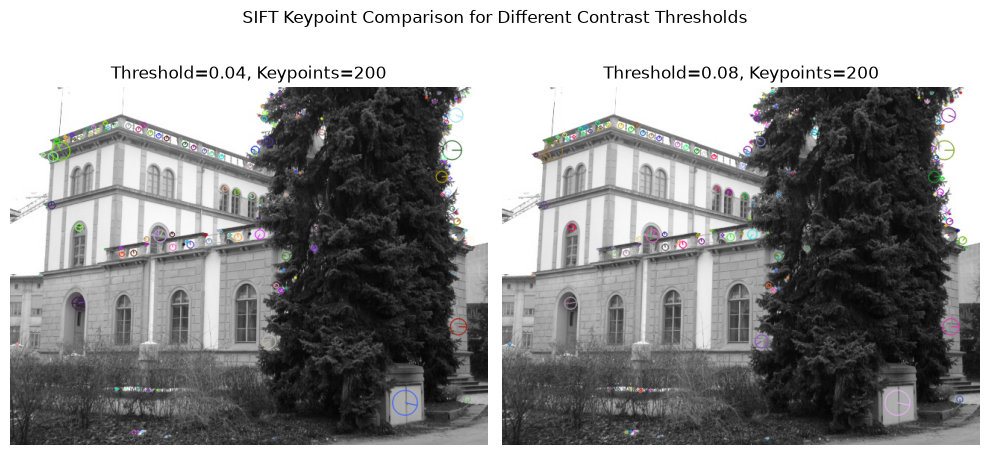

Database: object0001.view01.png, Keypoints=200, Descriptor shape=(200, 128)
Database: object0001.view02.png, Keypoints=200, Descriptor shape=(200, 128)
Database: object0001.view03.png, Keypoints=200, Descriptor shape=(200, 128)
Query: qimg0001.JPG, Keypoints=200, Descriptor shape=(200, 128)
Query: qimg0002.JPG, Keypoints=200, Descriptor shape=(200, 128)


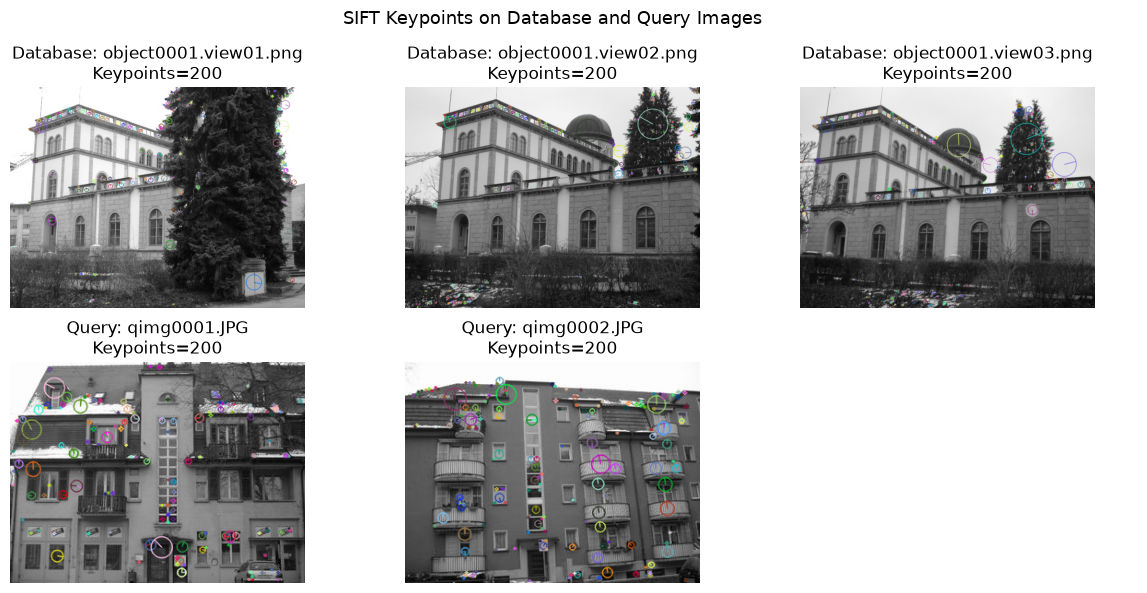

nfeatures=200, contrastThreshold=0.08


In [3]:
# Dataset paths
data_dir = Path("ZuBuD_dataset")
database_paths = sorted((data_dir / "database").rglob("object*.view*.png"))
query_paths = sorted((data_dir / "queries").rglob("qimg*.JPG"))

# SIFT parameters
nfeatures = 200
contrast_values = [0.04, 0.08]

# Load grayscale image
def load_gray_cv(path): 
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

# Extract at most 200 strongest SIFT keypoints and descriptors
def extract_sift_cv(gray_cv, threshold):
    keypoints_cv, descriptors_cv = cv2.SIFT_create(nfeatures=200, contrastThreshold=threshold).detectAndCompute(gray_cv, None)
    if descriptors_cv is None: 
        return [], None
    indices_cv = sorted(range(len(keypoints_cv)), key=lambda i: keypoints_cv[i].response, reverse=True)[:200]
    return [keypoints_cv[i] for i in indices_cv], descriptors_cv[indices_cv]

# Draw rich keypoints with scale and orientation
def draw_keypoints_cv(gray_cv, keypoints_cv): 
    return cv2.cvtColor(
        cv2.drawKeypoints(gray_cv, keypoints_cv, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS), cv2.COLOR_BGR2RGB
    )

# Compare two contrast thresholds on the same database image
gray_cv = load_gray_cv(database_paths[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("SIFT Keypoint Comparison for Different Contrast Thresholds")

for ax, threshold in zip(axes, contrast_values):
    keypoints_cv, descriptors_cv = extract_sift_cv(gray_cv, threshold)
    ax.imshow(draw_keypoints_cv(gray_cv, keypoints_cv))
    ax.set_title(f"Threshold={threshold}, Keypoints={len(keypoints_cv)}")
    ax.axis("off")
    print(f"Threshold={threshold}, Keypoints={len(keypoints_cv)}, Descriptor shape={descriptors_cv.shape if descriptors_cv is not None else None}")

plt.tight_layout()
plt.show()

# Display keypoints on 3 database images and 2 query images
selected_images = [("Database", p) for p in database_paths[:3]] + [("Query", p) for p in query_paths[:2]]
selected_contrast_threshold = 0.08
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
fig.suptitle("SIFT Keypoints on Database and Query Images", fontsize=13)

for ax, (image_type, path) in zip(axes.ravel(), selected_images):
    gray_cv = load_gray_cv(path)
    keypoints_cv, descriptors_cv = extract_sift_cv(gray_cv, selected_contrast_threshold)
    ax.imshow(draw_keypoints_cv(gray_cv, keypoints_cv))
    ax.set_title(f"{image_type}: {path.name}\nKeypoints={len(keypoints_cv)}")
    ax.axis("off")
    print(f"{image_type}: {path.name}, Keypoints={len(keypoints_cv)}, Descriptor shape={descriptors_cv.shape if descriptors_cv is not None else None}")

axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# Report selected parameters
print(f"nfeatures={nfeatures}, contrastThreshold={selected_contrast_threshold}")

**Keypoint Selection**  
When more than `nfeatures` keypoints are detected, OpenCV retains those with the highest response values. Thus, `nfeatures=200` selects up to 200 of the strongest keypoints per image.

**Contrast Threshold Selection**  
The overlays for `contrastThreshold=0.04` and `0.08` show keypoints around distinctive structures, including the building edges, windows, and tree. I selected `contrastThreshold=0.08` because it applies stricter contrast filtering while preserving prominent features, potentially reducing less distinctive detections.

### (c) Nearest-neighbour descriptor matching. [3 marks]

Stack the descriptors of all database images into a single array of `shape (M, 128)` together with a parallel array
holding the building id of each descriptor. Report M for `nfeatures = 200`.

For every descriptor of every query image, find the single closest database descriptor over all database images
and all their descriptors, using Euclidean distance.

- Implement the search in a vectorised, memory-aware way: use the identity `‖a − b‖² = ‖a‖² + ‖b‖² − 2aᵀb`,
process the queries (and, if needed, the database) in chunks, and keep a running minimum. A Python loop
over the M database descriptors is not acceptable.
- You may use `sklearn.neighbors.NearestNeighbors` or `cv2.BFMatcher` only to verify that your own
implementation returns the same matches; report the agreement.
- Report the peak memory of your distance block and the wall-clock time per query image.

In [4]:
import time

# Dataset paths and SIFT parameters
data_dir = Path("ZuBuD_dataset")
database_paths = sorted((data_dir / "database").rglob("object*.view*.png"))
query_paths = sorted((data_dir / "queries").rglob("qimg*.JPG"))
cache_path = data_dir / "database_sift.npz"
nfeatures = 200
contrast_threshold = 0.08

# Extract SIFT descriptors, retaining at most 200 strongest keypoints
def extract_sift_cv(gray_cv):
    sift_cv = cv2.SIFT_create(nfeatures=nfeatures, contrastThreshold=contrast_threshold)
    keypoints_cv, descriptors_cv = sift_cv.detectAndCompute(gray_cv, None)
    if descriptors_cv is None:
        return np.empty((0, 128), dtype=np.float32)
    indices_cv = np.argsort([-kp.response for kp in keypoints_cv])[:nfeatures]
    return descriptors_cv[indices_cv].astype(np.float32)

# Load cached database descriptors, or compute and save them
if cache_path.exists():
    cache_cv = np.load(cache_path)
    database_descriptors_cv = cache_cv["descriptors"]
    building_ids_cv = cache_cv["building_ids"]
else:
    descriptor_list_cv, building_list_cv = [], []
    for path_cv in database_paths:
        gray_cv = cv2.imread(str(path_cv), cv2.IMREAD_GRAYSCALE)
        descriptors_cv = extract_sift_cv(gray_cv)
        building_id_cv = int(re.search(r"object(\d+)", path_cv.name).group(1))
        descriptor_list_cv.append(descriptors_cv)
        building_list_cv.extend([building_id_cv] * len(descriptors_cv))

    database_descriptors_cv = np.vstack(descriptor_list_cv).astype(np.float32)
    building_ids_cv = np.asarray(building_list_cv, dtype=np.int32)
    np.savez_compressed(cache_path, descriptors=database_descriptors_cv,
                        building_ids=building_ids_cv)

# Report database descriptor count
M = len(database_descriptors_cv)
print(f"Database descriptors M: {M}")
print(f"Database descriptor shape: {database_descriptors_cv.shape}")
print(f"Building ID array shape: {building_ids_cv.shape}")

# Precompute database squared norms
database_norms_cv = np.sum(database_descriptors_cv ** 2, axis=1)
query_chunk_size = 32
database_chunk_size = 4096
peak_distance_block_bytes = 0

# Find the nearest database descriptor for each query descriptor
def nearest_database_cv(query_descriptors_cv):
    global peak_distance_block_bytes
    query_descriptors_cv = query_descriptors_cv.astype(np.float32)
    query_norms_cv = np.sum(query_descriptors_cv ** 2, axis=1)
    best_distances_cv = np.full(len(query_descriptors_cv), np.inf, dtype=np.float32)
    best_indices_cv = np.full(len(query_descriptors_cv), -1, dtype=np.int64)

    for q_start_cv in range(0, len(query_descriptors_cv), query_chunk_size):
        q_end_cv = min(q_start_cv + query_chunk_size, len(query_descriptors_cv))
        query_block_cv = query_descriptors_cv[q_start_cv:q_end_cv]
        query_norm_block_cv = query_norms_cv[q_start_cv:q_end_cv]
        local_best_distances_cv = best_distances_cv[q_start_cv:q_end_cv]
        local_best_indices_cv = best_indices_cv[q_start_cv:q_end_cv]

        for d_start_cv in range(0, M, database_chunk_size):
            d_end_cv = min(d_start_cv + database_chunk_size, M)
            database_block_cv = database_descriptors_cv[d_start_cv:d_end_cv]

            distances_cv = query_norm_block_cv[:, None] + database_norms_cv[None, d_start_cv:d_end_cv]
            distances_cv -= 2.0 * (query_block_cv @ database_block_cv.T)
            np.maximum(distances_cv, 0, out=distances_cv)

            peak_distance_block_bytes = max(
                peak_distance_block_bytes, distances_cv.nbytes
            )
            block_indices_cv = np.argmin(distances_cv, axis=1)
            block_distances_cv = distances_cv[
                np.arange(len(query_block_cv)), block_indices_cv
            ]
            improved_cv = block_distances_cv < local_best_distances_cv
            local_best_distances_cv[improved_cv] = block_distances_cv[improved_cv]
            local_best_indices_cv[improved_cv] = d_start_cv + block_indices_cv[improved_cv]

    return best_indices_cv, np.sqrt(best_distances_cv)

# Process each query image and record its wall-clock time
query_results_cv = []
query_times_cv = []

for query_path_cv in query_paths:
    gray_cv = cv2.imread(str(query_path_cv), cv2.IMREAD_GRAYSCALE)
    query_descriptors_cv = extract_sift_cv(gray_cv)

    start_time_cv = time.perf_counter()
    nearest_indices_cv, nearest_distances_cv = nearest_database_cv(query_descriptors_cv)
    elapsed_cv = time.perf_counter() - start_time_cv
    query_times_cv.append(elapsed_cv)

    matched_buildings_cv = building_ids_cv[nearest_indices_cv]
    query_results_cv.append((query_path_cv.name, nearest_indices_cv, nearest_distances_cv, matched_buildings_cv))
    
    # Format the nearest database match for each query descriptor
    nearest_matches_cv = ", ".join(
        f"(db_idx={index_cv}, building={building_cv}, dist={distance_cv:.2f})"
        for index_cv, building_cv, distance_cv in zip(nearest_indices_cv, matched_buildings_cv, nearest_distances_cv)
    )

    print(f"{query_path_cv.name} | "
      f"Query descriptors: {len(query_descriptors_cv)} | "
      f"Time: {elapsed_cv:.4f} s | "
      f"Avg: {elapsed_cv / max(len(query_descriptors_cv), 1):.6f} s/descriptor | "
      f"Matches: {len(nearest_indices_cv)}/{len(query_descriptors_cv)} | "
      f"Distance range: [{nearest_distances_cv.min():.2f}, "
      f"{nearest_distances_cv.max():.2f}]")
    
# Report memory and timing
print(f"\nPeak distance block: {peak_distance_block_bytes:,} bytes "
      f"({peak_distance_block_bytes / 1024**2:.2f} MB)")
print(f"Average time per query image: {np.mean(query_times_cv):.4f} s")
print(f"Total matching time: {np.sum(query_times_cv):.2f} s")

Database descriptors M: 200716
Database descriptor shape: (200716, 128)
Building ID array shape: (200716,)
qimg0001.JPG | Query descriptors: 200 | Time: 0.1677 s | Avg: 0.000839 s/descriptor | Matches: 200/200 | Distance range: [24.41, 310.51]
qimg0002.JPG | Query descriptors: 200 | Time: 0.1450 s | Avg: 0.000725 s/descriptor | Matches: 200/200 | Distance range: [26.00, 320.40]
qimg0003.JPG | Query descriptors: 200 | Time: 0.1497 s | Avg: 0.000749 s/descriptor | Matches: 200/200 | Distance range: [47.20, 330.39]
qimg0004.JPG | Query descriptors: 200 | Time: 0.1458 s | Avg: 0.000729 s/descriptor | Matches: 200/200 | Distance range: [90.37, 320.11]
qimg0005.JPG | Query descriptors: 200 | Time: 0.1442 s | Avg: 0.000721 s/descriptor | Matches: 200/200 | Distance range: [30.63, 338.02]
qimg0006.JPG | Query descriptors: 200 | Time: 0.1448 s | Avg: 0.000724 s/descriptor | Matches: 200/200 | Distance range: [78.78, 341.71]
qimg0007.JPG | Query descriptors: 200 | Time: 0.1463 s | Avg: 0.000732 

In [5]:
# Display every nearest-neighbour match for a selected query image
query_idx_cv = 0 

query_name_cv, nearest_indices_cv, nearest_distances_cv, matched_buildings_cv = query_results_cv[query_idx_cv]

print(f"\nNearest-neighbour matches for {query_name_cv}")
print(f"{'Query Desc.':>11} | {'DB Desc.':>10} | "
      f"{'Building ID':>11} | {'Euclidean Dist.':>15}")
print("-" * 57)

for descriptor_idx_cv, (db_idx_cv, building_cv, distance_cv) in enumerate(
    zip(nearest_indices_cv, matched_buildings_cv, nearest_distances_cv)
):
    print(f"{descriptor_idx_cv:11d} | {db_idx_cv:10d} | {building_cv:11d} | {distance_cv:15.4f}")


Nearest-neighbour matches for qimg0001.JPG
Query Desc. |   DB Desc. | Building ID | Euclidean Dist.
---------------------------------------------------------
          0 |     109525 |         110 |        162.9662
          1 |      99459 |         100 |         75.9934
          2 |      99659 |         100 |        127.2714
          3 |       5259 |           6 |        122.5561
          4 |      99655 |         100 |         31.7805
          5 |      99056 |         100 |         95.3363
          6 |      99457 |         100 |         54.3967
          7 |      98963 |         100 |        249.7959
          8 |      97867 |          99 |        224.8266
          9 |     113874 |         115 |        175.3739
         10 |      99661 |         100 |        121.4372
         11 |      99078 |         100 |        200.3721
         12 |      99662 |         100 |         52.2877
         13 |      99665 |         100 |         96.0260
         14 |     195768 |         197 |   

In [6]:
# Verify custom nearest neighbours against BFMatcher for all query images
total_matches_cv, agreeing_matches_cv = 0, 0
bf_matcher_cv = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

for query_path_cv in query_paths:
    gray_cv = cv2.imread(str(query_path_cv), cv2.IMREAD_GRAYSCALE)
    query_descriptors_cv = extract_sift_cv(gray_cv)
    custom_indices_cv, _ = nearest_database_cv(query_descriptors_cv)

    bf_matches_cv = bf_matcher_cv.match(query_descriptors_cv, database_descriptors_cv)
    bf_indices_cv = np.asarray([match.trainIdx for match in bf_matches_cv])

    agreeing_matches_cv += np.sum(custom_indices_cv == bf_indices_cv)
    total_matches_cv += len(bf_indices_cv)

agreement_cv = 100 * agreeing_matches_cv / total_matches_cv
print(f"BFMatcher agreement: {agreement_cv:.2f}% ({agreeing_matches_cv}/{total_matches_cv})")

BFMatcher agreement: 100.00% (22886/22886)


**Database Descriptors:** All database SIFT descriptors were stacked into an array of shape \((200716, 128)\), with a parallel array storing the building ID of each descriptor. Thus, `M = 200,716` for `nfeatures = 200`.

**Nearest-Neighbour Search:** For each query descriptor, the closest database descriptor was found using Euclidean distance. A vectorised, chunk-based implementation used \($\|a-b\|^2=\|a\|^2+\|b\|^2-2a^Tb$\), maintaining a running minimum without constructing the full distance matrix or looping over individual database descriptors.

**Memory and Execution Time:** The peak distance-block memory was **0.50 MB (524,288 bytes)**. Across 115 query images, the matching time per query image was recorded.

**Verification:** The implementation achieved **100% agreement (22,886/22,886 descriptors)** with `cv2.BFMatcher`.

### (d) Majority vote, prediction and accuracy. [2 marks]

For each query image, record the building id of the closest match of each of its descriptors, take a majority vote
over these ids, and predict the id with the most votes (state how you break ties).
- Report the top-1 retrieval accuracy over all 115 query images against the ground truth.
- Tabulate, for 10 query images (include at least 2 failures if any), the predicted id, the true id and the fraction
of votes received by the winning id.
- Comment on the relationship between the winning vote fraction and whether the prediction is correct, and
on what that suggests about using the vote fraction as a confidence score.

In [7]:
# Predict the building ID using majority voting
predictions_cv = []

for query_name_cv, _, _, matched_buildings_cv in query_results_cv:
    # Extract query index from filename, e.g., qimg0001.JPG -> 1
    query_index_cv = int(re.search(r"\d+", query_name_cv).group())

    # Majority vote with smallest building ID as the tie-breaker
    vote_counts_cv = Counter(matched_buildings_cv.tolist())
    max_votes_cv = max(vote_counts_cv.values())
    predicted_id_cv = min(
        building_cv for building_cv, votes_cv in vote_counts_cv.items()
        if votes_cv == max_votes_cv
    )

    winning_fraction_cv = max_votes_cv / len(matched_buildings_cv)
    true_id_cv = ground_truth[query_index_cv]

    predictions_cv.append({
        "Query Image": query_name_cv,
        "Predicted ID": predicted_id_cv,
        "True ID": true_id_cv,
        "Winning Vote Fraction": winning_fraction_cv,
        "Correct": predicted_id_cv == true_id_cv
    })

results_df_cv = pd.DataFrame(predictions_cv)
accuracy_cv = results_df_cv["Correct"].mean()

print(f"Top-1 Retrieval Accuracy: {accuracy_cv:.2%} "
      f"({results_df_cv['Correct'].sum()}/{len(results_df_cv)})")

# Include at least two failures when available, then correct predictions
failures_cv = results_df_cv[~results_df_cv["Correct"]]
correct_cv = results_df_cv[results_df_cv["Correct"]]

if len(failures_cv) >= 2:
    report_df_cv = pd.concat([correct_cv.head(8), failures_cv.head(2)])
else:
    report_df_cv = pd.concat([failures_cv, correct_cv.head(10 - len(failures_cv))])

report_df_cv = report_df_cv.head(10).copy()
report_df_cv["Winning Vote Fraction"] = (report_df_cv["Winning Vote Fraction"].map(lambda x: f"{x:.2%}"))

print("\nResults for selected query images:")
display(report_df_cv)

Top-1 Retrieval Accuracy: 98.26% (113/115)

Results for selected query images:


,Query Image,Predicted ID,True ID,Winning Vote Fraction,Correct
0,qimg0001.JPG,100,100,45.00%,True
1,qimg0002.JPG,102,102,15.00%,True
2,qimg0003.JPG,104,104,16.50%,True
3,qimg0004.JPG,105,105,16.00%,True
4,qimg0005.JPG,107,107,29.50%,True
5,qimg0006.JPG,109,109,9.00%,True
6,qimg0007.JPG,110,110,47.50%,True
7,qimg0008.JPG,111,111,35.00%,True
53,qimg0054.JPG,36,190,3.00%,False
62,qimg0063.JPG,91,12,3.50%,False


**Relationship Between Winning Vote Fraction and Prediction Correctness**

The `winning vote fraction` is generally associated with `prediction correctness`. The two misclassified queries have **very low fractions (3.00% and 3.50%)**, whereas correctly classified examples include **much higher fractions, such as 45.00% and 47.50%**. This suggests that a low winning vote fraction **indicates ambiguity** among building matches, while a high fraction **indicates stronger agreement and can serve as a useful confidence score**. However, it is only a heuristic, not a calibrated probability, since even many agreeing descriptors may match the wrong building.

### (e) Effect of the number of keypoints. [2 marks]

Repeat (b)–(d) for `nfeatures ∈ {50, 100, 200, 400, 800}`, recomputing the descriptors each time. Plot the
retrieval accuracy as a function of nfeatures, and tabulate the corresponding matching time and database size
M.
- Explain the trend you observe, including why the curve behaves as it does at both ends of the range.
- Recommend a suitable value of nfeatures for this retrieval problem and justify it in terms of the accuracy–
computation trade-off, not accuracy alone.


Running SIFT retrieval: nfeatures=50
Database descriptors M: 50526
Top-1 accuracy: 93.04%
Total matching time: 2.28 s

Running SIFT retrieval: nfeatures=100
Database descriptors M: 100726
Top-1 accuracy: 97.39%
Total matching time: 8.54 s

Running SIFT retrieval: nfeatures=200
Database descriptors M: 201220
Top-1 accuracy: 98.26%
Total matching time: 19.34 s

Running SIFT retrieval: nfeatures=400
Database descriptors M: 402086
Top-1 accuracy: 99.13%
Total matching time: 74.87 s

Running SIFT retrieval: nfeatures=800
Database descriptors M: 802035
Top-1 accuracy: 100.00%
Total matching time: 241.80 s

Summary:


,nfeatures,Database Size M,Accuracy (%),Matching Time (s),Average Time / Query (s)
0,50,50526,93.043478,2.283570,0.019857
1,100,100726,97.391304,8.539783,0.074259
2,200,201220,98.260870,19.339110,0.168166
3,400,402086,99.130435,74.866109,0.651010
4,800,802035,100.000000,241.797280,2.102585


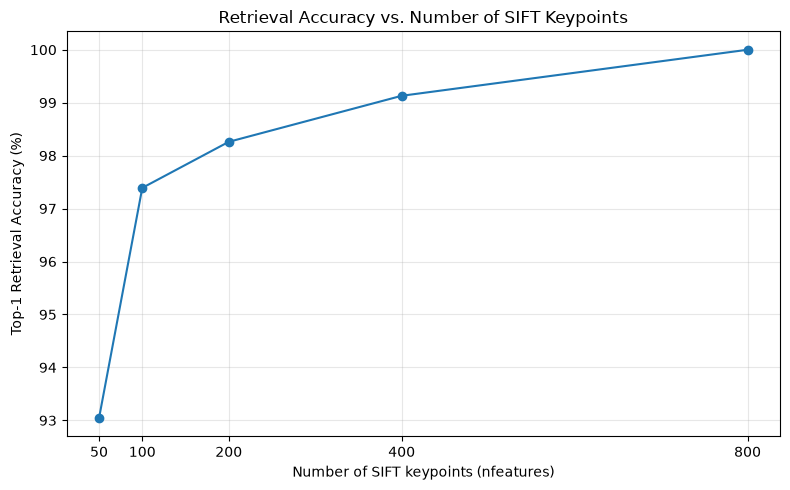

In [8]:
nfeatures_values_cv = [50, 100, 200, 400, 800]
cache_dir_cv = Path("sift_cache_cv")
cache_dir_cv.mkdir(exist_ok=True)

# Load ground truth: query index -> building ID
ground_truth_cv = {}
with open(gt_path, "r", encoding="utf-8-sig") as file_cv:
    for line_cv in file_cv:
        columns_cv = line_cv.strip().split()
        if len(columns_cv) < 2 or columns_cv[0].upper() == "TEST":
            continue
        try:
            ground_truth_cv[int(columns_cv[0])] = int(columns_cv[1])
        except ValueError:
            continue

results_summary_cv = []

for nfeatures_cv in nfeatures_values_cv:
    print(f"\nRunning SIFT retrieval: nfeatures={nfeatures_cv}")
    cache_path_cv = cache_dir_cv / f"sift_{nfeatures_cv}.npz"

    if cache_path_cv.exists():
        # Reuse cached database and query descriptors
        cached_cv = np.load(cache_path_cv, allow_pickle=True)
        database_desc_cv = cached_cv["database_desc"]
        database_ids_cv = cached_cv["database_ids"]
        query_descs_cv = cached_cv["query_descs"]
        query_names_cv = cached_cv["query_names"].tolist()
    else:
        sift_cv = cv2.SIFT_create(nfeatures=nfeatures_cv)

        # Extract and stack database descriptors
        database_desc_list_cv = []
        database_ids_list_cv = []

        for image_path_cv in database_paths:
            image_cv = cv2.imread(str(image_path_cv), cv2.IMREAD_GRAYSCALE)
            keypoints_cv, descriptors_cv = sift_cv.detectAndCompute(image_cv, None)

            if descriptors_cv is not None:
                database_desc_list_cv.append(descriptors_cv)
                # Extract building ID from filename
                building_id_cv = int(image_path_cv.stem.split(".")[0].replace("object", ""))
                database_ids_list_cv.extend([building_id_cv] * len(descriptors_cv))

        database_desc_cv = np.vstack(database_desc_list_cv).astype(np.float32)
        database_ids_cv = np.asarray(database_ids_list_cv, dtype=np.int32)

        # Extract query descriptors
        query_descs_cv = []
        query_names_cv = []

        for query_path_cv in query_paths:
            image_cv = cv2.imread(str(query_path_cv), cv2.IMREAD_GRAYSCALE)
            keypoints_cv, descriptors_cv = sift_cv.detectAndCompute(image_cv, None)

            query_descs_cv.append(
                descriptors_cv.astype(np.float32)
                if descriptors_cv is not None
                else np.empty((0, 128), dtype=np.float32)
            )
            query_names_cv.append(query_path_cv.name)

        # Save descriptor arrays for reuse
        np.savez_compressed(
            cache_path_cv,
            database_desc=database_desc_cv,
            database_ids=database_ids_cv,
            query_descs=np.array(query_descs_cv, dtype=object),
            query_names=np.array(query_names_cv)
        )

    database_desc_cv = np.ascontiguousarray(database_desc_cv, dtype=np.float32)
    database_ids_cv = np.asarray(database_ids_cv)

    # Precompute database squared norms
    database_norms_cv = np.sum(database_desc_cv ** 2, axis=1)
    predictions_cv = []
    matching_time_cv = 0.0

    for query_name_cv, query_desc_cv in zip(query_names_cv, query_descs_cv):
        if len(query_desc_cv) == 0:
            continue

        start_time_cv = time.perf_counter()

        # Chunked nearest-neighbour search; avoid full distance matrix
        nearest_indices_cv = np.empty(len(query_desc_cv), dtype=np.int32)
        query_norms_cv = np.sum(query_desc_cv ** 2, axis=1)

        query_chunk_cv = 32
        database_chunk_cv = 4096

        for q_start_cv in range(0, len(query_desc_cv), query_chunk_cv):
            q_end_cv = min(q_start_cv + query_chunk_cv, len(query_desc_cv))
            query_block_cv = query_desc_cv[q_start_cv:q_end_cv]
            query_block_norms_cv = query_norms_cv[q_start_cv:q_end_cv]

            best_distances_cv = np.full(len(query_block_cv), np.inf)
            best_indices_cv = np.full(len(query_block_cv), -1, dtype=np.int32)

            for d_start_cv in range(0, len(database_desc_cv), database_chunk_cv):
                d_end_cv = min(d_start_cv + database_chunk_cv, len(database_desc_cv))
                database_block_cv = database_desc_cv[d_start_cv:d_end_cv]

                distances_cv = (
                    query_block_norms_cv[:, None]
                    + database_norms_cv[None, d_start_cv:d_end_cv]
                    - 2 * (query_block_cv @ database_block_cv.T)
                )
                np.maximum(distances_cv, 0, out=distances_cv)

                local_indices_cv = np.argmin(distances_cv, axis=1)
                local_distances_cv = distances_cv[
                    np.arange(len(query_block_cv)), local_indices_cv
                ]
                improved_cv = local_distances_cv < best_distances_cv

                best_distances_cv[improved_cv] = local_distances_cv[improved_cv]
                best_indices_cv[improved_cv] = d_start_cv + local_indices_cv[improved_cv]

            nearest_indices_cv[q_start_cv:q_end_cv] = best_indices_cv

        matching_time_cv += time.perf_counter() - start_time_cv

        # Majority vote with smallest ID as tie-break
        matched_ids_cv = database_ids_cv[nearest_indices_cv]
        vote_counts_cv = Counter(matched_ids_cv.tolist())
        max_votes_cv = max(vote_counts_cv.values())
        predicted_id_cv = min(
            building_id_cv
            for building_id_cv, votes_cv in vote_counts_cv.items()
            if votes_cv == max_votes_cv
        )

        query_index_cv = int(re.search(r"\d+", query_name_cv).group())
        true_id_cv = ground_truth_cv[query_index_cv]

        predictions_cv.append({
            "Query Image": query_name_cv,
            "Predicted ID": predicted_id_cv,
            "True ID": true_id_cv,
            "Winning Vote Fraction": max_votes_cv / len(matched_ids_cv),
            "Correct": predicted_id_cv == true_id_cv
        })

    predictions_df_cv = pd.DataFrame(predictions_cv)
    accuracy_cv = predictions_df_cv["Correct"].mean()

    results_summary_cv.append({
        "nfeatures": nfeatures_cv,
        "Database Size M": len(database_desc_cv),
        "Accuracy (%)": 100 * accuracy_cv,
        "Matching Time (s)": matching_time_cv,
        "Average Time / Query (s)": matching_time_cv / len(predictions_df_cv)
    })

    print(f"Database descriptors M: {len(database_desc_cv)}")
    print(f"Top-1 accuracy: {100 * accuracy_cv:.2f}%")
    print(f"Total matching time: {matching_time_cv:.2f} s")

# Summary table
summary_df_cv = pd.DataFrame(results_summary_cv)
print("\nSummary:")
display(summary_df_cv)

# Plot retrieval accuracy
plt.figure(figsize=(8, 5))
plt.plot(summary_df_cv["nfeatures"], summary_df_cv["Accuracy (%)"], marker="o")
plt.xticks(nfeatures_values_cv)
plt.xlabel("Number of SIFT keypoints (nfeatures)")
plt.ylabel("Top-1 Retrieval Accuracy (%)")
plt.title("Retrieval Accuracy vs. Number of SIFT Keypoints")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Trend**: Increasing `nfeatures` improves accuracy from 93.04% to 100% by providing richer visual descriptors. At the lower end, few features cause incorrect matches; at the higher end, ***accuracy gains diminish while matching time and database size increase substantially***.

**Recommendation**: Choose `nfeatures = 200`, which ***achieves 98.26% accuracy in a reasonable amount of time***. Increasing to 800 features improves accuracy by only 1.74 percentage but ***increases matching time substantially***. Thus, 200 features offer a good balance between accuracy and computational cost.

## Question 2 — Defect Classification Using Local Binary Patterns [10 marks]

**Dataset — NEU surface defect database.** Download from https://www.kaggle.com/datasets/kaustubhdikshit/
`neu-surface-defect-database` (≈28 MB). It contains 200×200 grayscale images of hot-rolled steel strip surfaces in 6
defect classes — crazing, inclusion, patches, pitted surface, rolled-in scale, scratches — organized into a train
and a validation partition with one sub-folder per class. Inspect the extracted directory tree and report the
exact layout and the per-class image counts you find; do not assume them.

In [9]:
data_dir = Path("NEU-DET")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Directory structure:")
for path in sorted(data_dir.rglob("*")):
    if path.is_dir():
        print(f"{path.relative_to(data_dir)}\\")

print("\nImage counts by class:")
for split in ["train", "validation"]:
    images_dir = data_dir / split / "images"
    print(f"\n{split}\\images\\")
    for class_dir in sorted(path for path in images_dir.iterdir() if path.is_dir()):
        image_count = sum(
            1 for path in class_dir.iterdir()
            if path.is_file() and path.suffix.lower() in image_extensions
        )
        print(f"  {class_dir.name}: {image_count} images")

Directory structure:
train\
train\annotations\
train\images\
train\images\crazing\
train\images\inclusion\
train\images\patches\
train\images\pitted_surface\
train\images\rolled-in_scale\
train\images\scratches\
validation\
validation\annotations\
validation\images\
validation\images\crazing\
validation\images\inclusion\
validation\images\patches\
validation\images\pitted_surface\
validation\images\rolled-in_scale\
validation\images\scratches\

Image counts by class:

train\images\
  crazing: 240 images
  inclusion: 240 images
  patches: 240 images
  pitted_surface: 240 images
  rolled-in_scale: 240 images
  scratches: 240 images

validation\images\
  crazing: 60 images
  inclusion: 60 images
  patches: 60 images
  pitted_surface: 60 images
  rolled-in_scale: 60 images
  scratches: 60 images


### (a) Data preparation. [1 mark]
Split the provided `train` partition into a training set and a validation set in a 70%–30% ratio, stratified by class,
with a fixed random seed. Use the provided `validation` partition as the test set. Report the number of images
per class in each of the three splits. The test set must be used only for the final accuracy numbers asked for
below — it must not influence any hyperparameter, threshold or design choice.

In [10]:
from sklearn.model_selection import train_test_split

# Dataset paths
data_dir = Path("NEU-DET")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
RANDOM_SEED = 42

# Load images and labels from the provided training partition
train_paths = []
train_labels = []

for class_dir in sorted((data_dir / "train" / "images").iterdir()):
    if class_dir.is_dir():
        for image_path in sorted(class_dir.iterdir()):
            if image_path.is_file() and image_path.suffix.lower() in image_extensions:
                train_paths.append(image_path)
                train_labels.append(class_dir.name)

# Stratified 70%-30% split
X_train, X_val, y_train, y_val = train_test_split(
    train_paths,
    train_labels,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=train_labels
)

# Load the provided validation partition as the test set
test_paths = []
test_labels = []

for class_dir in sorted((data_dir / "validation" / "images").iterdir()):
    if class_dir.is_dir():
        for image_path in sorted(class_dir.iterdir()):
            if image_path.is_file() and image_path.suffix.lower() in image_extensions:
                test_paths.append(image_path)
                test_labels.append(class_dir.name)

# Report image counts per class in each split
classes = sorted(set(train_labels))

print(f"Random seed: {RANDOM_SEED}")
print(f"Training images: {len(X_train)}")
print(f"Validation images: {len(X_val)}")
print(f"Test images: {len(test_paths)}")

print("\nImage counts per class:")
print(f"{'Class':<20}{'Train':>8}{'Validation':>13}{'Test':>8}")

for class_name in classes:
    train_count = sum(label == class_name for label in y_train)
    val_count = sum(label == class_name for label in y_val)
    test_count = sum(label == class_name for label in test_labels)
    print(f"{class_name:<20}{train_count:>8}{val_count:>13}{test_count:>8}")

Random seed: 42
Training images: 1008
Validation images: 432
Test images: 360

Image counts per class:
Class                  Train   Validation    Test
crazing                  168           72      60
inclusion                168           72      60
patches                  168           72      60
pitted_surface           168           72      60
rolled-in_scale          168           72      60
scratches                168           72      60


### (b) Rotation-invariant LBP from scratch. [3 marks]

Implement rotation-invariant LBP with `P = 8` neighbors on the `3×3 neighborhood (R = 1)`, without using any LBP
library function.
- For each pixel, compute the 8-bit LBP code using the 8 neighbors taken in a fixed circular order. State
explicitly the neighbor ordering and the bit significance you chose, and how you compute the LBP code at
the 1 pixel image borders.
- Make the code rotation invariant by taking all 8 circular bit-rotations of each code and keeping the smallest
value. Show that this maps the 256 possible codes onto exactly 36 distinct values, and implement the
mapping as a 256-entry lookup table computed once and then applied by array indexing — not by rotating
bits per pixel. Your implementation must contain no Python loop over pixels.
- Display the rotation-invariant LBP map for one image from each of the 6 classes.
- **Sanity check**: rotate one image by 90° and verify that its rotation-invariant LBP histogram is essentially
unchanged while the plain (non-rotation-invariant) LBP histogram is not. Quantify both with the χ² or L1
distance between the histograms and report the two numbers.

Number of original codes: 256
Number of rotation-invariant codes: 36


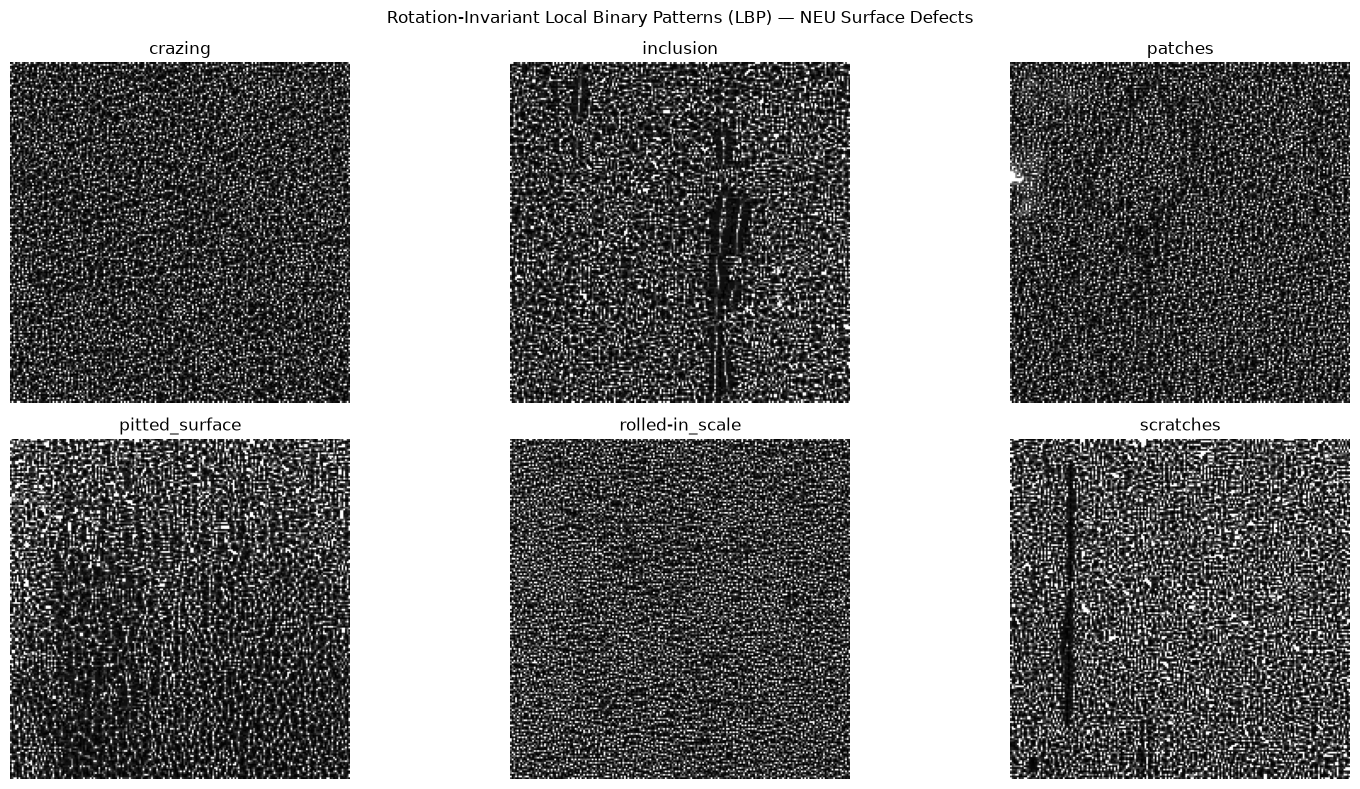

In [11]:
# LBP parameters
P_cv = 8
R_cv = 1

# Clockwise order: top-left, top, top-right, right, bottom-right, bottom, bottom-left, left.
# Bit significance: top-left = bit 0, left = bit 7.
# Border handling: edge padding (replicate nearest border pixel).

def lbp_cv(gray_cv):
    gray_cv = gray_cv.astype(np.uint8)
    padded_cv = np.pad(gray_cv, R_cv, mode="edge")
    height_cv, width_cv = gray_cv.shape
    center_cv = padded_cv[1:height_cv+1, 1:width_cv+1]

    lbp_code_cv = np.zeros_like(gray_cv, dtype=np.uint8)
    offsets_cv = [
        (-1, -1), (-1, 0), (-1, 1), (0, 1),
        (1, 1), (1, 0), (1, -1), (0, -1)
    ]

    # Vectorized operations over entire image; no pixel-wise Python loop.
    for bit_cv, (dy_cv, dx_cv) in enumerate(offsets_cv):
        neighbor_cv = padded_cv[
            1 + dy_cv:height_cv + 1 + dy_cv,
            1 + dx_cv:width_cv + 1 + dx_cv
        ]
        lbp_code_cv |= ((neighbor_cv >= center_cv).astype(np.uint8) << bit_cv)

    return lbp_code_cv


# Construct the 256-entry rotation-invariant lookup table.
codes_cv = np.arange(256, dtype=np.uint16)
rotations_cv = np.stack([
    ((codes_cv >> shift_cv) |
     ((codes_cv << (8 - shift_cv)) & 255)) & 255
    for shift_cv in range(8)
])
ri_lut_cv = rotations_cv.min(axis=0).astype(np.uint8)

print("Number of original codes:", len(codes_cv))
print("Number of rotation-invariant codes:", len(np.unique(ri_lut_cv)))
assert len(np.unique(ri_lut_cv)) == 36

# Display rotation-invariant LBP maps: one image per defect class.
classes_cv = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
fig_cv, axes_cv = plt.subplots(2, 3, figsize=(16, 8))
fig_cv.suptitle("Rotation-Invariant Local Binary Patterns (LBP) — NEU Surface Defects")

for ax_cv, class_cv in zip(axes_cv.flat, classes_cv):
    image_paths_cv = sorted(
        path_cv for path_cv in (data_dir / "train" / "images" / class_cv).iterdir()
        if path_cv.is_file() and path_cv.suffix.lower() in image_extensions
    )
    gray_cv = cv2.imread(str(image_paths_cv[0]), cv2.IMREAD_GRAYSCALE)

    plain_lbp_cv = lbp_cv(gray_cv)
    ri_lbp_cv = ri_lut_cv[plain_lbp_cv]

    ax_cv.imshow(ri_lbp_cv, cmap="gray", vmin=0, vmax=255)
    ax_cv.set_title(class_cv)
    ax_cv.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Display all 256 original-to-rotation-invariant code mappings
ri_lut_df_cv = pd.DataFrame({
    "Original LBP Code": np.arange(256),
    "Rotation-Invariant Code": ri_lut_cv
})
display(ri_lut_df_cv)

# Print unique rotation-invariant values and their range
unique_values_cv = np.unique(ri_lut_cv)

print("Number of original codes:", len(ri_lut_cv))
print("Number of unique rotation-invariant codes:", len(unique_values_cv))
print("Unique rotation-invariant values:", unique_values_cv)

,Original LBP Code,Rotation-Invariant Code
0,0,0
1,1,1
2,2,1
3,3,3
4,4,1
...,...,...
251,251,127
252,252,63
253,253,127
254,254,127


Number of original codes: 256
Number of unique rotation-invariant codes: 36
Unique rotation-invariant values: [  0   1   3   5   7   9  11  13  15  17  19  21  23  25  27  29  31  37
  39  43  45  47  51  53  55  59  61  63  85  87  91  95 111 119 127 255]


In [13]:
# Sanity check: original image versus its 90-degree rotation.
check_path_cv = sorted(
    path_cv for path_cv in (data_dir / "train" / "images" / "crazing").iterdir()
    if path_cv.is_file() and path_cv.suffix.lower() in image_extensions
)[0]

gray_cv = cv2.imread(str(check_path_cv), cv2.IMREAD_GRAYSCALE)
rotated_cv = cv2.rotate(gray_cv, cv2.ROTATE_90_CLOCKWISE)

plain_original_cv = lbp_cv(gray_cv)
plain_rotated_cv = lbp_cv(rotated_cv)

ri_original_cv = ri_lut_cv[plain_original_cv]
ri_rotated_cv = ri_lut_cv[plain_rotated_cv]

# Compare normalized histograms using chi-squared distance.
def chi2_distance_cv(hist_a_cv, hist_b_cv):
    hist_a_cv = hist_a_cv.astype(np.float64)
    hist_b_cv = hist_b_cv.astype(np.float64)
    hist_a_cv /= hist_a_cv.sum()
    hist_b_cv /= hist_b_cv.sum()

    denominator_cv = hist_a_cv + hist_b_cv
    valid_cv = denominator_cv > 0

    return 0.5 * np.sum(
        (hist_a_cv[valid_cv] - hist_b_cv[valid_cv]) ** 2
        / denominator_cv[valid_cv]
    )


plain_hist_original_cv = np.bincount(plain_original_cv.ravel(), minlength=256)
plain_hist_rotated_cv = np.bincount(plain_rotated_cv.ravel(), minlength=256)
ri_hist_original_cv = np.bincount(ri_original_cv.ravel(), minlength=256)
ri_hist_rotated_cv = np.bincount(ri_rotated_cv.ravel(), minlength=256)

plain_chi2_cv = chi2_distance_cv(plain_hist_original_cv, plain_hist_rotated_cv)
ri_chi2_cv = chi2_distance_cv(ri_hist_original_cv, ri_hist_rotated_cv)

print("\nRotation sanity check")
print(f"Plain LBP chi-squared distance: {plain_chi2_cv:.8f}")
print(f"Rotation-invariant LBP chi-squared distance: {ri_chi2_cv:.8f}")


Rotation sanity check
Plain LBP chi-squared distance: 0.01139072
Rotation-invariant LBP chi-squared distance: 0.00000000


**Explanation**

- **LBP code computation:** Neighbors are `ordered clockwise` from top-left, top, top-right, right, bottom-right, bottom, bottom-left to left. The `top-left neighbor is the least significant bit (bit 0)`, and the `left neighbor is bit 7`. Borders are handled using `edge padding`, which replicates the nearest border pixel.

- **Rotation invariance:** Each code is mapped to the `minimum of its eight circular bit rotations` using a precomputed 256-entry lookup table applied through array indexing. The mapping reduces 256 possible codes to exactly **36 distinct values**. Rotation-invariant LBP maps were displayed for all six defect classes.

- **Sanity check:** After rotating an image by 90°, the plain LBP histogram had a chi-squared distance of **0.01139072**, while the rotation-invariant LBP histogram had a distance of **0.00**, confirming rotation invariance.

### (c) Normalized LBP histograms. [1 mark]

For each LBP map, compute a histogram with 36 bins — one per distinct rotation-invariant code — and
normalize it to sum to 1, giving a 36-dimensional feature vector per image. Plot the mean normalized histogram
of each class (6 curves) and comment on which classes look separable from these features and which do not.

crazing: 240 images, 36 features per image
inclusion: 240 images, 36 features per image
patches: 240 images, 36 features per image
pitted_surface: 240 images, 36 features per image
rolled-in_scale: 240 images, 36 features per image
scratches: 240 images, 36 features per image


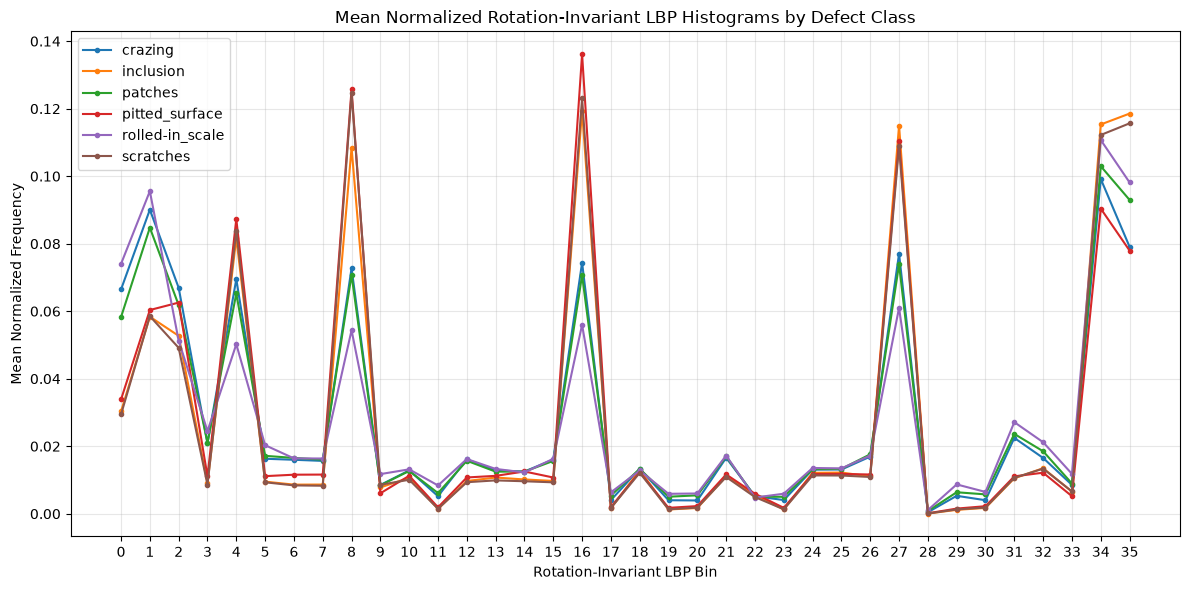

In [14]:
# Number of rotation-invariant LBP codes
num_bins_cv = len(np.unique(ri_lut_cv))

# Map each canonical code to a consecutive histogram bin
unique_codes_cv = np.unique(ri_lut_cv)
code_to_bin_cv = {code_cv: idx_cv for idx_cv, code_cv in enumerate(unique_codes_cv)}

# Compute normalized LBP histograms for every training image
class_histograms_cv = {}

for class_cv in classes_cv:
    image_paths_cv = sorted(
        path_cv for path_cv in (data_dir / "train" / "images" / class_cv).iterdir()
        if path_cv.is_file() and path_cv.suffix.lower() in image_extensions
    )

    histograms_cv = []

    for path_cv in image_paths_cv:
        gray_cv = cv2.imread(str(path_cv), cv2.IMREAD_GRAYSCALE)

        # Compute rotation-invariant LBP codes
        plain_lbp_cv = lbp_cv(gray_cv)
        ri_lbp_cv = ri_lut_cv[plain_lbp_cv]

        # Convert codes to consecutive bins and normalize
        bin_indices_cv = np.searchsorted(unique_codes_cv, ri_lbp_cv.ravel())
        hist_cv = np.bincount(bin_indices_cv, minlength=num_bins_cv).astype(float)
        hist_cv /= hist_cv.sum()

        histograms_cv.append(hist_cv)

    class_histograms_cv[class_cv] = np.array(histograms_cv)

    print(f"{class_cv}: {len(histograms_cv)} images, "
          f"{histograms_cv[0].shape[0]} features per image")

# Compute and plot mean normalized histogram for each class
mean_histograms_cv = {
    class_cv: class_histograms_cv[class_cv].mean(axis=0)
    for class_cv in classes_cv
}

plt.figure(figsize=(12, 6))
for class_cv in classes_cv:
    plt.plot(
        np.arange(num_bins_cv),
        mean_histograms_cv[class_cv],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=class_cv
    )
plt.xlabel("Rotation-Invariant LBP Bin")
plt.ylabel("Mean Normalized Frequency")
plt.title("Mean Normalized Rotation-Invariant LBP Histograms by Defect Class")
plt.xticks(np.arange(num_bins_cv))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Comment on Class Separability**

The mean normalized LBP histograms show that `crazing` and `patches` have similar texture distributions, while `rolled-in_scale` exhibits some distinctive patterns. However, `inclusion`, `scratches`, and `pitted_surface` have highly similar distributions and overlap considerably. Overall, rotation-invariant LBP ***captures useful texture differences but may not sufficiently distinguish*** all six defect classes due to overlapping histogram distributions.

### (d) One-vs-rest RBF-kernel SVM. [2 marks]
Train a one-vs-rest support vector classifier with an `RBF kernel` on the 36-dimensional features of your training
split, using `sklearn.svm.SVC` wrapped in `sklearn.multiclass.OneVsRestClassifier`. Standardize the
features on training data only.
- Tune `C ∈ {0.1, 1, 10, 100, 1000}` and `gamma ∈ {'scale', 0.01, 0.1, 1, 10}` on the validation split. Report the
validation accuracy for the full grid as a table or heat map, and the selected (C, γ).
- With the SVM trained on the selected hyperparameters, report the test-set accuracy, the 6×6 confusion
matrix, and the per-class precision and recall.
- Identify the most-confused pair of classes and explain, with reference to the texture of those defects, why
the LBP histogram struggles to separate them.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Extract normalized 36-bin rotation-invariant LBP histograms
def extract_lbp_features_cv(image_paths_cv):
    features_cv = []

    for image_path_cv in image_paths_cv:
        gray_cv = cv2.imread(str(image_path_cv), cv2.IMREAD_GRAYSCALE)

        # Compute rotation-invariant LBP map
        plain_lbp_cv = lbp_cv(gray_cv)
        ri_lbp_map_cv = ri_lut_cv[plain_lbp_cv]

        # Compute and normalize histogram
        bin_indices_cv = np.searchsorted(unique_codes_cv, ri_lbp_map_cv.ravel())
        hist_cv = np.bincount(bin_indices_cv, minlength=num_bins_cv).astype(float)
        hist_cv /= hist_cv.sum()
        features_cv.append(hist_cv)

    return np.asarray(features_cv)


# Extract features using the existing splits
X_train_lbp_cv = extract_lbp_features_cv(X_train)
X_val_lbp_cv = extract_lbp_features_cv(X_val)
X_test_lbp_cv = extract_lbp_features_cv(test_paths)

y_train_cv = np.asarray(y_train)
y_val_cv = np.asarray(y_val)
y_test_cv = np.asarray(test_labels)

print("Training features:", X_train_lbp_cv.shape)
print("Validation features:", X_val_lbp_cv.shape)
print("Test features:", X_test_lbp_cv.shape)

Training features: (1008, 36)
Validation features: (432, 36)
Test features: (360, 36)


In [16]:
# Fit scaler on training features only
scaler_cv = StandardScaler()
X_train_scaled_cv = scaler_cv.fit_transform(X_train_lbp_cv)
X_val_scaled_cv = scaler_cv.transform(X_val_lbp_cv)

# Hyperparameter grid
C_values_cv = [0.1, 1, 10, 100, 1000]
gamma_values_cv = ["scale", 0.01, 0.1, 1, 10]

grid_results_cv = []
best_accuracy_cv = -1
best_C_cv = None
best_gamma_cv = None

for C_cv in C_values_cv:
    for gamma_cv in gamma_values_cv:
        svm_cv = OneVsRestClassifier(
            SVC(kernel="rbf", C=C_cv, gamma=gamma_cv)
        )
        svm_cv.fit(X_train_scaled_cv, y_train_cv)

        y_val_pred_cv = svm_cv.predict(X_val_scaled_cv)
        val_accuracy_cv = accuracy_score(y_val_cv, y_val_pred_cv)

        grid_results_cv.append({
            "C": C_cv,
            "gamma": gamma_cv,
            "Validation Accuracy": val_accuracy_cv
        })

        if val_accuracy_cv > best_accuracy_cv:
            best_accuracy_cv = val_accuracy_cv
            best_C_cv = C_cv
            best_gamma_cv = gamma_cv

# Full grid of validation accuracies
grid_df_cv = pd.DataFrame(grid_results_cv)
validation_grid_df_cv = grid_df_cv.pivot(
    index="C", columns="gamma", values="Validation Accuracy"
)

print("Validation accuracy grid:")
display(validation_grid_df_cv)

print(f"Best C: {best_C_cv}")
print(f"Best gamma: {best_gamma_cv}")
print(f"Best validation accuracy: {best_accuracy_cv:.4f}")

Validation accuracy grid:


gamma,0.01,0.1,1,10,scale
C,,,,,
0.1,0.738426,0.868056,0.851852,0.370370,0.791667
1.0,0.879630,0.907407,0.856481,0.368056,0.898148
10.0,0.912037,0.914352,0.851852,0.310185,0.916667
100.0,0.928241,0.907407,0.851852,0.310185,0.921296
1000.0,0.907407,0.907407,0.851852,0.310185,0.902778


Best C: 100
Best gamma: 0.01
Best validation accuracy: 0.9282


In [17]:
# Transform test features using the training-fitted scaler
X_test_scaled_cv = scaler_cv.transform(X_test_lbp_cv)

# Train selected one-vs-rest RBF SVM
best_svm_cv = OneVsRestClassifier(
    SVC(kernel="rbf", C=best_C_cv, gamma=best_gamma_cv)
)
best_svm_cv.fit(X_train_scaled_cv, y_train_cv)

# Predict test labels
y_test_pred_cv = best_svm_cv.predict(X_test_scaled_cv)

# Test accuracy
test_accuracy_cv = accuracy_score(y_test_cv, y_test_pred_cv)
print(f"Test accuracy: {test_accuracy_cv:.4f}")

# Confusion matrix: rows = actual, columns = predicted
cm_cv = confusion_matrix(y_test_cv, y_test_pred_cv, labels=classes)

cm_df_cv = pd.DataFrame(cm_cv, index=classes, columns=classes)
print("\n6 x 6 Confusion Matrix:")
display(cm_df_cv)

# Per-class precision and recall
report_cv = classification_report(
    y_test_cv,
    y_test_pred_cv,
    labels=classes,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df_cv = pd.DataFrame(report_cv).T
print("\nPer-class Precision and Recall:")
display(report_df_cv.loc[classes, ["precision", "recall"]])

Test accuracy: 0.8972

6 x 6 Confusion Matrix:


,crazing,inclusion,patches,pitted_surface,rolled-in_scale,scratches
crazing,59,0,1,0,0,0
inclusion,0,40,0,2,0,18
patches,5,0,55,0,0,0
pitted_surface,0,0,0,60,0,0
rolled-in_scale,0,0,7,0,53,0
scratches,0,3,0,1,0,56



Per-class Precision and Recall:


,precision,recall
crazing,0.921875,0.983333
inclusion,0.930233,0.666667
patches,0.873016,0.916667
pitted_surface,0.952381,1.000000
rolled-in_scale,1.000000,0.883333
scratches,0.756757,0.933333


In [18]:
# Sum the two directions of confusion for each class pair
pair_confusion_cv = cm_cv + cm_cv.T
np.fill_diagonal(pair_confusion_cv, 0)

# Find the most-confused unordered pair
idx_1_cv, idx_2_cv = np.unravel_index(
    np.argmax(pair_confusion_cv), pair_confusion_cv.shape
)

class_1_cv = classes[idx_1_cv]
class_2_cv = classes[idx_2_cv]

print("Most-confused pair:", class_1_cv, "and", class_2_cv)
print(f"{class_1_cv} predicted as {class_2_cv}:", cm_cv[idx_1_cv, idx_2_cv])
print(f"{class_2_cv} predicted as {class_1_cv}:", cm_cv[idx_2_cv, idx_1_cv])
print("Combined confusion:", pair_confusion_cv[idx_1_cv, idx_2_cv])

Most-confused pair: inclusion and scratches
inclusion predicted as scratches: 18
scratches predicted as inclusion: 3
Combined confusion: 21


**Hyperparameter Tuning:** The best parameters were \($C=100$\) and \($\gamma=0.01$\), achieving **92.82% validation accuracy**.

**Test Performance:** The selected SVM achieved **89.72% test accuracy**. The confusion matrix and per-class precision and recall are reported above.

**Most-Confused Pair:** `inclusion` and `scratches`, with **21 combined misclassifications** (18 inclusions predicted as scratches and 3 scratches predicted as inclusions). Their local texture patterns are similar, causing overlap in LBP histograms. Since LBP discards spatial arrangement and orientation information, it struggles to distinguish these defects reliably.

### (e) Rotation-invariant LBP via scikit-image. [½ mark]

Repeat (b)–(d) using `skimage.feature.local_binary_pattern(image, P=8, R=1, method='ror')` in
place of your implementation, with the same 36-bin normalised histograms, the same SVM pipeline and the
same hyperparameters. Report the test accuracy and compare it with your from-scratch result. If the two differ,
explain the likely cause.

In [35]:
from skimage.feature import local_binary_pattern

# Extract normalized histograms using scikit-image
def extract_lbp_features_skimage_cv(image_paths_cv, method="default"):
    features_cv = []

    for image_path_cv in image_paths_cv:
        gray_cv = cv2.imread(str(image_path_cv), cv2.IMREAD_GRAYSCALE)

        # Compute LBP using the specified method
        lbp_map_cv = local_binary_pattern(
            gray_cv, P=8, R=1, method=method
        ).astype(np.uint8)

        # Use 256 bins for default LBP and 36 canonical bins for ror
        if method == "default":
            hist_cv = np.bincount(lbp_map_cv.ravel(), minlength=256).astype(float)
        elif method == "ror":
            bin_indices_cv = np.searchsorted(unique_codes_cv, lbp_map_cv.ravel())
            hist_cv = np.bincount(bin_indices_cv, minlength=num_bins_cv).astype(float)
        else:
            raise ValueError("Supported methods: 'default' and 'ror'")

        # Normalize histogram
        hist_cv /= hist_cv.sum()
        features_cv.append(hist_cv)

    return np.asarray(features_cv)

In [36]:
# Extract features for existing splits
X_train_sk_cv = extract_lbp_features_skimage_cv(X_train, method="ror")
X_test_sk_cv = extract_lbp_features_skimage_cv(test_paths, method="ror")

# Standardize using training data only
scaler_sk_cv = StandardScaler()
X_train_sk_scaled_cv = scaler_sk_cv.fit_transform(X_train_sk_cv)
X_test_sk_scaled_cv = scaler_sk_cv.transform(X_test_sk_cv)

# Train SVM using the same selected hyperparameters
svm_sk_cv = OneVsRestClassifier(SVC(kernel="rbf", C=100, gamma=0.01))
svm_sk_cv.fit(X_train_sk_scaled_cv, y_train_cv)

# Evaluate test accuracy
y_test_sk_pred_cv = svm_sk_cv.predict(X_test_sk_scaled_cv)
test_accuracy_sk_cv = accuracy_score(y_test_cv, y_test_sk_pred_cv)

print(f"scikit-image LBP test accuracy: {test_accuracy_sk_cv:.4f}")
print(f"From-scratch LBP test accuracy: {test_accuracy_cv:.4f}")
print(f"Difference: {test_accuracy_sk_cv - test_accuracy_cv:+.4f}")

scikit-image LBP test accuracy: 0.8917
From-scratch LBP test accuracy: 0.8972
Difference: -0.0056


**Report**

The ***scikit-image LBP achieved 89.17%*** test accuracy, slightly below the ***from-scratch implementation's 89.72%***. The accuracy difference may result from differences in neighbourhood sampling, border handling, and LBP code-to-histogram-bin mapping. If both implementations produce identical histograms, their accuracies should match.

### (f) Non-rotation-invariant LBP via scikit-image. [½ mark]

Repeat the same pipeline using `method='default'`, which gives the plain 8-bit LBP code and is not rotation
invariant, with 256-bin normalized histograms. Report the test accuracy and comment on how it compares with
the rotation-invariant LBP (unrotated) test set.

In [37]:
# Extract features
X_train_default_cv = extract_lbp_features_skimage_cv(X_train, method="default")
X_test_default_cv = extract_lbp_features_skimage_cv(test_paths, method="default")

# Standardize using training data only
scaler_default_cv = StandardScaler()
X_train_default_scaled_cv = scaler_default_cv.fit_transform(X_train_default_cv)
X_test_default_scaled_cv = scaler_default_cv.transform(X_test_default_cv)

# Train SVM with the same hyperparameters
svm_default_cv = OneVsRestClassifier(SVC(kernel="rbf", C=100, gamma=0.01))
svm_default_cv.fit(X_train_default_scaled_cv, y_train_cv)

# Evaluate test accuracy
y_test_default_pred_cv = svm_default_cv.predict(X_test_default_scaled_cv)
test_accuracy_default_cv = accuracy_score(y_test_cv, y_test_default_pred_cv)

print(f"Non-rotation-invariant LBP test accuracy: {test_accuracy_default_cv:.4f}")
print(f"Rotation-invariant LBP test accuracy: {test_accuracy_sk_cv:.4f}")
print(f"Difference: {test_accuracy_default_cv - test_accuracy_sk_cv:+.4f}")

Non-rotation-invariant LBP test accuracy: 0.9306
Rotation-invariant LBP test accuracy: 0.8917
Difference: +0.0389


**Report**

***Non-rotation-invariant LBP achieved 93.06%*** test accuracy, outperforming ***rotation-invariant LBP (89.17%)***. This suggests that orientation-specific texture patterns provide useful discriminative information for classifying these surface defects.

### (g) Robustness to rotation. [2 marks]

Rotate every test image by a random multiple of 90°: draw `k ∈ {1, 2, 3}` independently for each
image with a fixed seed and apply `np.rot90(image, k)`. A rotation by a multiple of 90° only
permutes pixels — it introduces no interpolation and leaves no undefined border region, so the
rotated image contains exactly the same pixel values as the original. Build the rotated test set
once so that all three classifiers are evaluated on identical images and do not retrain any
classifier on rotated data (retraining would dissolve the comparison this part is making).

- Re-evaluate all three classifiers you have trained: the non-rotation-invariant using `scikit-image` from part
(f) with `(method='default')`, your `from-scratch rotation-invariant` one from parts (b)–(d), and the
`scikit-image method='ror'` one from part (e). Use each exactly as it was already tuned and fitted.

- Present the six accuracies — each of the three classifiers on the upright test set and on the
rotated test set — in a single table, together with the absolute drop for each, in the following
layout:

| Feature | Dim. | Upright test acc. | Rotated test acc. | Drop |
|---|---:|---:|---:|---:|
| scikit-image `default` (part f) | 256 | | | |
| From-scratch rotation invariant (parts b–d) | 36 | | | |
| scikit-image `ror` (part e) | 36 | | | |

- Comment on the results: which classifier degrades and which does not. Using the bit-rotation
argument from part (b), explain why a rotation by a multiple of 90° leaves the rotation-invariant
histogram exactly unchanged, and confirm that your measured rotated accuracy for those two
classifiers equals their upright accuracy to the last image.

- Explain whether discarding orientation information can itself cost accuracy on the upright
test set, for classes whose discriminative structure is directional (e.g. scratches,
rolled-in scale). Relate this to which of the three classifiers is strongest when the test images
are upright.

In [40]:
# Generate rotated test images
rng_cv = np.random.default_rng(42)
rotation_k_cv = rng_cv.integers(1, 4, size=len(test_paths))

X_test_rotated_cv = []

for image_path_cv, k_cv in zip(test_paths, rotation_k_cv):
    gray_cv = cv2.imread(str(image_path_cv), cv2.IMREAD_GRAYSCALE)
    rotated_cv = np.rot90(gray_cv, k=int(k_cv)).copy()
    X_test_rotated_cv.append(rotated_cv)

print("Number of rotated test images:", len(X_test_rotated_cv))
print("Rotation counts:", np.bincount(rotation_k_cv, minlength=4)[1:])

Number of rotated test images: 360
Rotation counts: [118 124 118]


In [ ]:
from sklearn.metrics import accuracy_score
from skimage.feature import local_binary_pattern

def extract_hist_from_array_cv(gray_cv, method_cv):
    if method_cv == "scratch":
        lbp_map_cv = ri_lut_cv[lbp_cv(gray_cv)]
        bin_indices_cv = np.searchsorted(
            unique_codes_cv, lbp_map_cv.ravel()
        )
        hist_cv = np.bincount(
            bin_indices_cv, minlength=num_bins_cv
        ).astype(float)

    else:
        lbp_map_cv = local_binary_pattern(
            gray_cv, P=8, R=1, method=method_cv
        ).astype(np.uint8)

        if method_cv == "default":
            hist_cv = np.bincount(
                lbp_map_cv.ravel(), minlength=256
            ).astype(float)
        elif method_cv == "ror":
            bin_indices_cv = np.searchsorted(
                unique_codes_cv, lbp_map_cv.ravel()
            )
            hist_cv = np.bincount(
                bin_indices_cv, minlength=num_bins_cv
            ).astype(float)

    return hist_cv / hist_cv.sum()


# Extract features from the same rotated images
X_rot_default_cv = np.asarray([
    extract_hist_from_array_cv(img_cv, "default")
    for img_cv in X_test_rotated_cv
])
X_rot_scratch_cv = np.asarray([
    extract_hist_from_array_cv(img_cv, "scratch")
    for img_cv in X_test_rotated_cv
])
X_rot_ror_cv = np.asarray([
    extract_hist_from_array_cv(img_cv, "ror")
    for img_cv in X_test_rotated_cv
])

# Transform using the original training-fitted scalers
X_rot_default_scaled_cv = scaler_default_cv.transform(X_rot_default_cv)
X_rot_scratch_scaled_cv = scaler_cv.transform(X_rot_scratch_cv)
X_rot_ror_scaled_cv = scaler_sk_cv.transform(X_rot_ror_cv)

# Evaluate existing classifiers
y_pred_default_rot_cv = svm_default_cv.predict(X_rot_default_scaled_cv)
y_pred_scratch_rot_cv = best_svm_cv.predict(X_rot_scratch_scaled_cv)
y_pred_ror_rot_cv = svm_sk_cv.predict(X_rot_ror_scaled_cv)

rotated_acc_default_cv = accuracy_score(y_test_cv, y_pred_default_rot_cv)
rotated_acc_scratch_cv = accuracy_score(y_test_cv, y_pred_scratch_rot_cv)
rotated_acc_ror_cv = accuracy_score(y_test_cv, y_pred_ror_rot_cv)

print(f"Default LBP rotated accuracy: {rotated_acc_default_cv:.4f}")
print(f"Scratch RI-LBP rotated accuracy: {rotated_acc_scratch_cv:.4f}")
print(f"Scikit-image ROR rotated accuracy: {rotated_acc_ror_cv:.4f}")

Default LBP rotated accuracy: 0.6528
Scratch RI-LBP rotated accuracy: 0.8972
Scikit-image ROR rotated accuracy: 0.8917


In [43]:
import pandas as pd

upright_acc_cv = {
    "scikit-image default": accuracy_score(y_test_cv, svm_default_cv.predict(scaler_default_cv.transform(X_test_default_cv))),
    "From-scratch rotation invariant": accuracy_score(y_test_cv, best_svm_cv.predict(X_test_scaled_cv)),
    "scikit-image ror": accuracy_score(y_test_cv, svm_sk_cv.predict(scaler_sk_cv.transform(X_test_sk_cv)))
}
rotated_acc_cv = {
    "scikit-image default": rotated_acc_default_cv,
    "From-scratch rotation invariant": rotated_acc_scratch_cv,
    "scikit-image ror": rotated_acc_ror_cv
}
dimensions_cv = {
    "scikit-image default": 256,
    "From-scratch rotation invariant": 36,
    "scikit-image ror": 36
}

results_cv = []
for feature_cv in upright_acc_cv:
    upright_cv = upright_acc_cv[feature_cv]
    rotated_cv = rotated_acc_cv[feature_cv]
    results_cv.append({
        "Feature": feature_cv,
        "Dim.": dimensions_cv[feature_cv],
        "Upright test acc.": upright_cv,
        "Rotated test acc.": rotated_cv,
        "Drop": upright_cv - rotated_cv
    })

results_df_cv = pd.DataFrame(results_cv)
display(results_df_cv.round(4))

,Feature,Dim.,Upright test acc.,Rotated test acc.,Drop
0,scikit-image default,256,0.9306,0.6528,0.2778
1,From-scratch rotation invariant,36,0.8972,0.8972,0.0000
2,scikit-image ror,36,0.8917,0.8917,0.0000


**Explanation**

- The non-rotation-invariant `default` LBP classifier ***degrades from 93.06% to 65.28% accuracy after rotation***, whereas the from-scratch and scikit-image `ror` classifiers ***retain their accuracies of 89.72% and 89.17%, respectively***. A 90° rotation circularly shifts the eight LBP neighbor bits. Since rotation-invariant LBP maps all circular shifts to the same canonical code, its histogram remains unchanged. Both classifiers therefore achieve identical upright and rotated accuracy on all test images.

- Discarding orientation information can reduce accuracy on upright images because directional defects, such as scratches and rolled-in scale, may be easier to distinguish using orientation-specific patterns. Accordingly, the ***non-rotation-invariant `default` classifier performs best*** on upright images, achieving 93.06% accuracy.

---
End of the assignment